<a href="https://colab.research.google.com/github/anushagpatel/Fine_Tuning_Gretel_Text_to_SQL/blob/main/Gretel_Text_to_SQL_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

baseline: 10/100
baseline: 20/100
baseline: 30/100
baseline: 40/100
baseline: 50/100
baseline: 60/100
baseline: 70/100
baseline: 80/100
baseline: 90/100
baseline: 100/100


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Adding EOS to train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

The model is already on multiple devices. Skipping the move to device specified in `args`.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151645}.


trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815


Step,Training Loss
20,0.495800
40,0.451500
60,0.430600
80,0.435700
100,0.425000
120,0.415200
140,0.405000
160,0.425400
180,0.422000
200,0.403400


finetuned: 10/100
finetuned: 20/100
finetuned: 30/100
finetuned: 40/100
finetuned: 50/100
finetuned: 60/100
finetuned: 70/100
finetuned: 80/100
finetuned: 90/100
finetuned: 100/100
    model  exact_match  sql_validity  explanation_rate
 baseline         0.14           1.0               1.0
finetuned         0.26           1.0               1.0


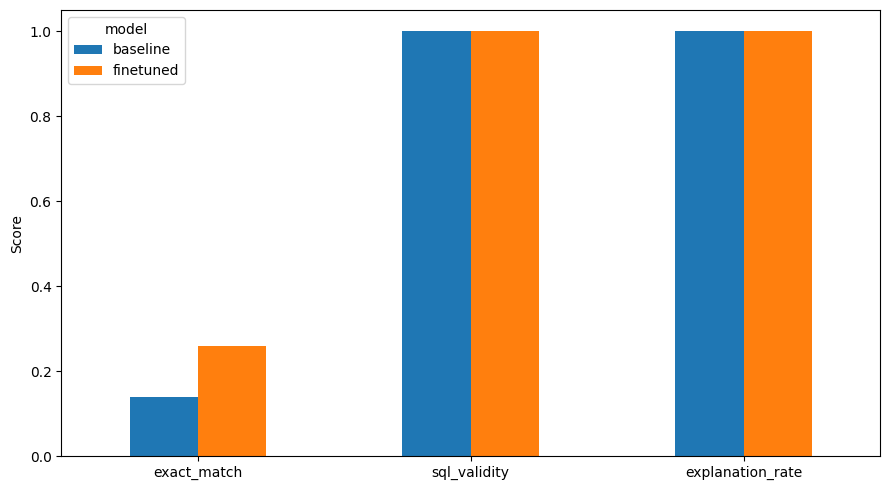

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7b94a3924975d4d95f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [22]:
import sys
import subprocess

subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"], check=False)
subprocess.run([
    sys.executable, "-m", "pip", "install", "-q", "-U",
    "transformers", "datasets", "peft", "trl", "accelerate",
     "sqlglot", "gradio", "pandas", "matplotlib"
], check=True)

import re
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt
import sqlglot
import gradio as gr

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    set_seed
)
from peft import LoraConfig, prepare_model_for_kbit_training
from trl import SFTConfig, SFTTrainer

SEED = 42
TRAIN_N = 2000
TEST_N = 100
MAX_LENGTH = 1024
MODEL_NAME = "Qwen/Qwen2.5-Coder-1.5B-Instruct"

OUT = Path("/content/text2sql_results")
OUT.mkdir(parents=True, exist_ok=True)

set_seed(SEED)

assert torch.cuda.is_available(), "Enable GPU in Colab runtime settings."

dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

dataset = load_dataset("gretelai/synthetic_text_to_sql")

train_data = (
    dataset["train"]
    .shuffle(seed=SEED)
    .select(range(min(TRAIN_N, len(dataset["train"]))))
)

test_data = (
    dataset["test"]
    .shuffle(seed=SEED)
    .select(range(min(TEST_N, len(dataset["test"]))))
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=dtype,
    device_map={"": 0}
)

# model = AutoModelForCausalLM.from_pretrained(
#     MODEL_NAME,
#     quantization_config=BitsAndBytesConfig(
#         load_in_4bit=True,
#         bnb_4bit_quant_type="nf4",
#         bnb_4bit_compute_dtype=dtype,
#         bnb_4bit_use_double_quant=True
#     ),
#     device_map={"": 0},
#     torch_dtype=dtype
# )


# Formats the database schema and question into model input messages.
def messages(schema, question):
    return [
        {
            "role": "system",
            "content": (
                "Generate SQL and a short explanation using the given schema. "
                "Format: SQL: followed by Explanation:"
            )
        },
        {
            "role": "user",
            "content": f"Database schema:\n{schema}\n\nQuestion:\n{question}"
        }
    ]


# Generates a response from the model using the schema and question.
def generate(model, schema, question):
    prompt = tokenizer.apply_chat_template(
        messages(schema, question),
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
    model.eval()

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    return tokenizer.decode(
        output[0, inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    ).strip()


# Extracts the SQL query from the model's response.
def extract_sql(response):
    match = re.search(
        r"SQL\s*:\s*(.*?)(?:\n\s*Explanation\s*:|$)",
        response,
        re.I | re.S
    )

    sql = match.group(1).strip() if match else response.strip()

    return re.sub(
        r"^```(?:sql)?\s*|\s*```$",
        "",
        sql,
        flags=re.I
    ).strip()


# Extracts the SQL explanation from the model's response.
def extract_explanation(response):
    match = re.search(
        r"Explanation\s*:\s*(.*)$",
        response,
        re.I | re.S
    )

    return match.group(1).strip() if match else ""


# Standardizes SQL formatting for comparison.
def normalize_sql(sql):
    try:
        return sqlglot.parse_one(sql).sql(
            pretty=False,
            normalize=True
        )
    except Exception:
        return re.sub(r"\s+", " ", sql.strip().lower())


# Checks whether the generated SQL has valid syntax.
def valid_sql(sql):
    try:
        return (
            bool(sql.strip())
            and sqlglot.parse_one(sql) is not None
        )
    except Exception:
        return False


# Evaluates model performance on the test dataset.
def evaluate(model, name):
    records = []

    for i, example in enumerate(test_data):
        response = generate(
            model,
            example["sql_context"],
            example["sql_prompt"]
        )

        sql = extract_sql(response)
        explanation = extract_explanation(response)

        records.append({
            "question": example["sql_prompt"],
            "expected_sql": example["sql"],
            "predicted_sql": sql,
            "explanation": explanation,
            "exact_match": (
                normalize_sql(sql)
                == normalize_sql(example["sql"])
            ),
            "sql_validity": valid_sql(sql),
            "explanation_rate": bool(explanation)
        })

        if (i + 1) % 10 == 0:
            print(f"{name}: {i + 1}/{len(test_data)}")

    df = pd.DataFrame(records)

    df.to_csv(
        OUT / f"{name}_predictions.csv",
        index=False
    )

    return {
        "model": name,
        "exact_match": df["exact_match"].mean(),
        "sql_validity": df["sql_validity"].mean(),
        "explanation_rate": df["explanation_rate"].mean()
    }, df


baseline_metrics, baseline_df = evaluate(model, "baseline")


# Converts dataset records into training prompts and expected responses.
def prepare(example):
    prompt = tokenizer.apply_chat_template(
        messages(
            example["sql_context"],
            example["sql_prompt"]
        ),
        tokenize=False,
        add_generation_prompt=True
    )

    completion = (
        f"SQL:\n{example['sql']}\n\n"
        f"Explanation:\n{example['sql_explanation']}"
        f"{tokenizer.eos_token}"
    )

    return {
        "prompt": prompt,
        "completion": completion
    }


train_ds = train_data.map(
    prepare,
    remove_columns=train_data.column_names
)

model.config.use_cache = False
model.gradient_checkpointing_enable()

lora = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ]
)

args = SFTConfig(
    output_dir=str(OUT / "checkpoints"),
    num_train_epochs=1,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    logging_steps=20,
    save_strategy="epoch",
    save_total_limit=1,
    report_to="none",
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    gradient_checkpointing=True,
    fp16=dtype == torch.float16,
    bf16=dtype == torch.bfloat16,
    seed=SEED
)

trainer = SFTTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    peft_config=lora,
    processing_class=tokenizer
)

trainer.model.print_trainable_parameters()
trainer.train()

trainer.save_model(str(OUT / "lora_adapter"))
tokenizer.save_pretrained(str(OUT / "lora_adapter"))

finetuned_model = trainer.model
finetuned_model.config.use_cache = True

finetuned_metrics, finetuned_df = evaluate(
    finetuned_model,
    "finetuned"
)

results = pd.DataFrame([
    baseline_metrics,
    finetuned_metrics
])

results.to_csv(
    OUT / "metrics.csv",
    index=False
)

print(results.to_string(index=False))

comparison = pd.DataFrame({
    "question": baseline_df["question"],
    "expected_sql": baseline_df["expected_sql"],
    "baseline_sql": baseline_df["predicted_sql"],
    "finetuned_sql": finetuned_df["predicted_sql"],
    "baseline_match": baseline_df["exact_match"],
    "finetuned_match": finetuned_df["exact_match"]
})

comparison.to_csv(
    OUT / "predictions.csv",
    index=False
)

ax = results.set_index("model")[
    ["exact_match", "sql_validity", "explanation_rate"]
].T.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig(OUT / "results.png", dpi=200)
plt.show()


# Generates SQL and explanations for the Gradio interface.
def predict(schema, question):
    if not schema.strip() or not question.strip():
        return "", "Enter a schema and question."

    response = generate(
        finetuned_model,
        schema,
        question
    )

    return (
        extract_sql(response),
        extract_explanation(response)
    )


demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Textbox(
            label="Database Schema",
            lines=8
        ),
        gr.Textbox(
            label="Question",
            lines=2
        )
    ],
    outputs=[
        gr.Code(
            label="Generated SQL",
            language="sql"
        ),
        gr.Textbox(
            label="Explanation",
            lines=4
        )
    ],
    title="Text-to-SQL"
)

demo.launch(share=True)